# Counting barnacles with Mask R-CNN

The aim is to help count individual barnacles inside a sampling frame. I split the experiment into two parts: recovering usable instance labels from the supplied blue contours, and testing whether a pretrained model could produce separate barnacle predictions.

This notebook follows that process from the first inspection crop to the saved prediction overlays. The overlays are useful for seeing where the model's count might be wrong, especially when several predictions fall on the same barnacle.


## Before running the notebook

Open the notebook from the project root, alongside `Barnacles/` and `requirements.txt`. The README gives installation instructions using Python 3.10, the version used for the Discovery experiment.

The inspection and region selectors can run locally. The **Model experiment** section needs CUDA-enabled PyTorch and an NVIDIA GPU. To look at the finished run without training anything, go straight to **Results** and run its code cell; it only reads the saved figures and summaries.


In [ ]:
%pip install -q -r requirements.txt

## Understanding the photographs and annotations

I first compare the original photograph with its contour image. Those two files have matching coordinates. The supplied cropped overlay is helpful for seeing what was annotated, but its coordinates do not line up with the full photograph, so I do not use it to build the labels.


In [2]:
# Paths are relative to the project root.
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

data_dir = Path("Barnacles")
assert data_dir.is_dir(), "The Barnacles folder is necessary and should be placed inside the working directory"

Photograph: (2448, 3264, 3) uint8
Annotation: (2448, 3264, 3) uint8


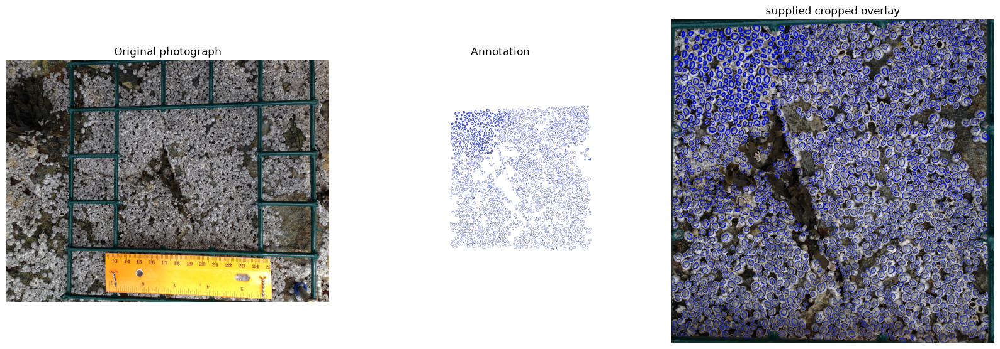

In [3]:
# Load the photograph and its aligned contour annotation.
with Image.open(data_dir / "img1.png") as image:
    original_photo = np.array(image.convert("RGB")) 
                     
with Image.open(data_dir / "mask1.png") as image:
    annotation = np.array(image.convert("RGB"))

print("Photograph:", original_photo.shape, original_photo.dtype)
print("Annotation:", annotation.shape, annotation.dtype)

assert original_photo.shape == annotation.shape, "Photo and annotation must align"

# Compare the aligned inputs with the supplied cropped overlay.
with Image.open(data_dir / "masked_img1.png") as image:
    supplied_overlay = np.array(image.convert("RGB"))

fig, axes = plt.subplots(1, 3, figsize=(16,6))

for ax, pixels, title in zip(axes, [original_photo, annotation, supplied_overlay], ["Original photograph", "Annotation", "supplied cropped overlay"]):
    ax.imshow(pixels)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Looking closely at a few outlines

At full resolution, there are too many contours to judge how they separate neighboring barnacles. A small inspection crop makes it easier to see whether the blue boundaries are closed, broken, or touching.

The sliders below move a 300 × 300 crop, and the yellow rectangle shows its position in the full photograph. They start at the position used in the recorded experiment.


In [4]:
# Widgets provide the sliders displayed inside the notebook
import ipywidgets as widgets
from matplotlib.patches import Rectangle

# Keep the inspection crop at 300 × 300 original-image pixels.
crop_size = 300

def preview_crop(x0, y0, original_photo, crop_size):
    # Show where the proposed crop lies in the original photograph
    fig, ax = plt.subplots(figsize=(7,5))
    ax.imshow(original_photo)
    
    # x0/y0 set the upper-left corner, crop_size sets width and height
    ax.add_patch(Rectangle(
        (x0, y0),
        crop_size,
        crop_size,
        fill=False,
        edgecolor="yellow",
        linewidth=2
    ))
    ax.set_title(f"Inspection crop: x0={x0}, y0={y0}")
    ax.axis("off")
    plt.show()

from IPython.display import display

# Pass the slider values to preview_crop().
crop_controls = widgets.interactive(
    preview_crop,
    # These inputs stay fixed while the sliders move.
    original_photo =widgets.fixed(original_photo),
    crop_size=widgets.fixed(crop_size),
    # Move the crop horizontally.
    # Start at the recorded position and keep the crop's right edge inside the photograph.
    x0=widgets.IntSlider(
        value=1850,
        min=0,
        max=original_photo.shape[1] - crop_size,
        description="x0",
        continuous_update=False
    ),
    # Move the crop vertically.
    # Keep the crop's bottom edge inside the photograph.
    y0=widgets.IntSlider(
        value=1073,
        min=0,
        max=original_photo.shape[0]-crop_size,
        description="y0",
        continuous_update=False
    )
)

# The widget's children are the sliders followed by its output area.
sliders = crop_controls.children[:-1]
preview_output=crop_controls.children[-1]

# Stack the sliders vertically.
left_panel = widgets.VBox(sliders)

# Put the controls on the left and the preview on the right.
crop_layout = widgets.HBox(
    [left_panel, preview_output],
    layout=widgets.Layout(align_items="center"),
)

# Display the controls beside the preview.
display(crop_layout)

The recorded crop starts at `x0=1850, y0=1073`. I take the same rows and columns from the photograph and annotation so I can compare them directly. Some barnacles are cut by the crop edge; at this stage, I focus on the outlines fully inside it.


Selected region: x0=1850, y0=1073, size=300


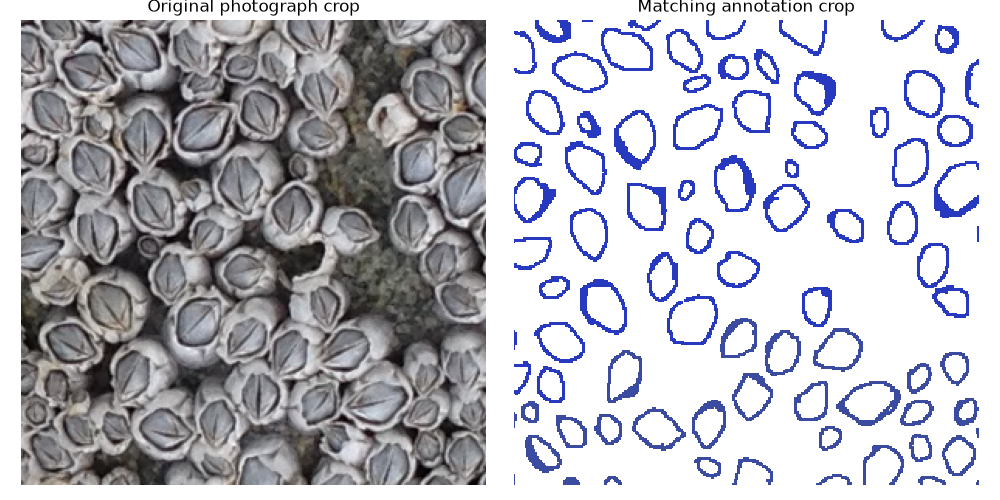

In [17]:
# Read the last arguments passed to preview_crop().

x0 = crop_controls.kwargs["x0"]
y0 = crop_controls.kwargs["y0"]
# Take exactly the same crop from the photograph and annotation.
# NumPy indexes images as [row, column], or [y, x].
photo_crop = original_photo[
    y0:y0+crop_size,
    x0:x0+crop_size
]

annotation_crop = annotation[
    y0:y0 + crop_size,
    x0:x0 + crop_size
]

print(f"Selected region: x0={x0}, y0={y0}, size={crop_size}")

# Check alignment by displaying the crops side by side.
fig, axes = plt.subplots(1, 2, figsize=(10,5))
axes[0].imshow(photo_crop)
axes[0].set_title("Original photograph crop")
# Nearest-neighbor display keeps thin outlines from being blurred.
# as interpolation method uses the closest original pixel's color without blending neighbors, 
# This changes the display, not the annotation array.
axes[1].imshow(annotation_crop, interpolation="nearest")
axes[1].set_title("Matching annotation crop")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Isolating the blue annotation lines

RGB is convenient for displaying the images. For selecting the blue outlines, I use HSV, which separates hue from saturation and brightness. The pixel picker lets me inspect actual annotation colors before choosing a filtering range.


In [18]:
import cv2
annotation_hsv = cv2.cvtColor(annotation_crop, cv2.COLOR_RGB2HSV)

def inspect_pixel(pixel_x, pixel_y, annotation_crop, annotation_hsv):
    rgb = annotation_crop[pixel_y, pixel_x] # RGB value at the selected pixel.
    hsv = annotation_hsv[pixel_y, pixel_x] # HSV value used to inspect the annotation color.

    fig, ax = plt.subplots(figsize=(5,5))
    # Show the original RGB annotation.
    ax.imshow(annotation_crop, interpolation="nearest")
    # Mark the pixel whose color is being inspected.
    ax.plot(pixel_x, pixel_y, "r+", markersize=12)
    ax.set_title(
        f"Pixel: ({pixel_x}, {pixel_y})\n"
        f"HSV: {hsv}",
        fontsize=10
    )
    ax.axis("off")
    plt.show()

# The coordinates below are local to the annotation crop
pixel_picker = widgets.interactive(
    inspect_pixel,
    # Pass both image representations as fixed inputs.
    annotation_crop=widgets.fixed(annotation_crop),
    annotation_hsv=widgets.fixed(annotation_hsv),
    # Pixel indices run from 0 to one less than the image dimension.
    pixel_x=widgets.IntSlider(
        value=annotation_crop.shape[1]//2, # Start near the center of the crop.
        min=0,
        max=annotation_crop.shape[1] - 1,
        description="Pixel x",
        continuous_update=True
    ),
    pixel_y = widgets.IntSlider(
        value=annotation_crop.shape[0]//2,
        min=0,
        max=annotation_crop.shape[0] - 1,
        description="Pixel y",
        continuous_update=True
    )
)
# Keep the controls beside their preview.
pixel_controls = widgets.VBox(pixel_picker.children[:-1])
pixel_output = pixel_picker.children[-1]

display(widgets.HBox(
    [pixel_controls, pixel_output],
    layout=widgets.Layout(align_items="center")
))

The points below are the blue pixels I recorded in this inspection crop. Their coordinates are local to the crop. If the crop is moved, these points need to be chosen again before calculating new color bounds.


In [20]:
# These (x, y) positions belong to the recorded inspection crop.
outline_points=[
    (151, 102),
    (71,88),
    (230, 259),
    (27, 245),
    (294,117),
    (67, 81)
    
]
# Read the HSV color at each recorded blue pixel.
hsv_samples = []

for pixel_x, pixel_y in outline_points:
    hsv_samples.append(annotation_hsv[pixel_y][pixel_x])

# Each row contains the hue, saturation, and value of one sampled pixel.
hsv_samples = np.array(hsv_samples)
print("Sampled HSV values:")
print(hsv_samples)

# Take the minimum and maximum separately for each HSV channel.
# axis=0 compares the sampled pixels down each column.
lower_blue = hsv_samples.min(axis=0)
upper_blue = hsv_samples.max(axis=0)
print("Minimum H,S,V:", lower_blue)
print("Maximum H,S,V:", upper_blue)

Sampled HSV values:
[[116 203 191]
 [116 203 191]
 [115 161 160]
 [116 203 191]
 [116 203 191]
 [116 203 191]]
Minimum H,S,V: [115 161 160]
Maximum H,S,V: [116 203 191]


I use the lowest and highest measured HSV values as the initial color bounds. This includes the sampled pixels, but it may still miss other shades along the contours.

After extracting the blue lines, I invert the binary image. The lines become black barriers, while the spaces between them become white regions that connected-components labeling can separate.


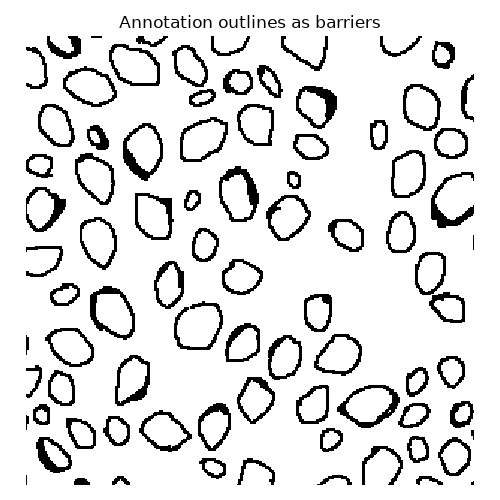

In [21]:
def extract_outlines(annotation_rgb, lower_blue, upper_blue):
    # Extract annotation pixels within the measured HSV range.
    # The same function accepts an inspection crop or a full annotation.
    # Convert RGB colors to HSV before filtering.
    annotation_hsv = cv2.cvtColor(
        annotation_rgb,
        cv2.COLOR_RGB2HSV,
    )

    # A pixel must satisfy all three inclusive color bounds.
    # Selected outline pixels become 255; all other pixels become 0.
    outlines = cv2.inRange(
        annotation_hsv,
        lower_blue,
        upper_blue
    )
    return outlines
    
blue_outlines = extract_outlines(annotation_crop, lower_blue, upper_blue)

# Invert the mask so the outlines act as black barriers.
# Both candidate interiors and the surrounding background become white.
non_outline_pixels = cv2.bitwise_not(blue_outlines)
plt.figure(figsize=(5,5))

# Show the binary values without blending neighboring pixels.
# This makes gaps in the extracted outlines easier to see.
plt.imshow(
    non_outline_pixels,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

plt.title("Annotation outlines as barriers")
plt.axis("off")
plt.tight_layout()
plt.show()

### Recovering candidate interiors

Connected-components labeling gives each connected white region an ID. I use four-way connectivity, so pixels connect above, below, left, and right. The black outline pixels remain label 0.


In [22]:
def label_regions(non_outline_pixels):
    # Group nonzero pixels into connected regions.
    # Four-way connectivity joins pixels above, below, left, and right.
    # The outline pixels remain label 0.
    #
    # returns:
    #    number_of_labels: total number of labels, including label 0
    #    region_labels: an image-sized array of integer region IDs
    #
    # example:
    # 1  1  0  2
    # 1  1  0  2
    # 1  1  0  2
    
    number_of_labels, region_labels = cv2.connectedComponents(
        non_outline_pixels,
        connectivity=4
    )
    return number_of_labels, region_labels
number_of_labels, region_labels = label_regions(non_outline_pixels)

The surrounding background reaches the crop border, and some barnacles are cut by it. I remove regions touching any edge to avoid treating those open areas as complete interiors. Label 0 is also excluded because it represents the outline pixels.


In [23]:
def select_enclosed_regions(number_of_labels, region_labels):
    # Find the region IDs along each edge of the crop.
    
    top_edge = region_labels[0, :]
    bottom_edge = region_labels[-1, :]
    left_edge = region_labels[:, 0]
    right_edge = region_labels[:, -1]
    
    # example
    # 1  1  1  0  3
    # 1  0  0  0  3
    # 1  0  2  0  3
    # 1  0  0  0  3
    # 1  1  1  0  3
    # The four edge arrays in this example are:
    # top_edge = [1,  1,  1,  0,  3]
    # bottom_edge = [1, 1, 1, 0, 3]
    # left_edge = [1, 1, 1, 1, 1]
    # right_edge = [3, 3, 3, 3, 3]
    # Combine the edges and find the distinct region IDs they contain.
    
    border_labels = np.unique(np.concatenate([
        top_edge,
        bottom_edge,
        left_edge,
        right_edge
    ]))
    
    # Start by keeping every region, then mark the exclusions.
    keep = np.ones(number_of_labels, dtype=bool)
    # Label 0 belongs to the outlines.
    keep[0] = False
    # Remove regions that reach a crop edge.
    keep[border_labels] = False
    return keep
keep = select_enclosed_regions(number_of_labels, region_labels)

The retained regions still have their original component IDs. I map them to consecutive instance IDs starting at 1, with 0 reserved for excluded pixels. This produces one label map in which each candidate interior has its own number.


In [24]:
def assign_instance_ids(region_labels, keep):
    # Build consecutive IDs by counting the True entries in keep.
    #
    # example:
    # Original region IDs = [0,     1,     2,    3,     4]
    # keep:                 [False, False, True, False, True]
    # after cumsum:         [0,     0,     1,    1,     2]
    
    label_lookup = np.cumsum(keep, dtype=np.int32)
    
    # Give rejected regions the background ID.
    # ~keep selects the rejected entries.
    # example of final lookup:  [0, 0, 1, 0, 2]
    label_lookup[~keep] = 0
    
    # Use each pixel's component ID to look up its new instance ID.
    #
    # Example component IDs: [1, 0, 2, 2, 0, 4, 3]
    # resulting instance IDs: [0, 0, 1, 1, 0, 2, 0]
    candidate_instances = label_lookup[region_labels]
    
    # Count the retained regions.
    instance_count = int(keep.sum())
    return candidate_instances, instance_count

candidate_instances, instance_count = assign_instance_ids(
    region_labels,
    keep
)
print(f"Number of enclosed candidate regions: {instance_count}")

Number of enclosed candidate regions: 62


I overlay the candidate interiors on the photograph to check their positions and look for missing regions or contours that have joined together. These are automatically recovered candidates, not manually verified instance masks.


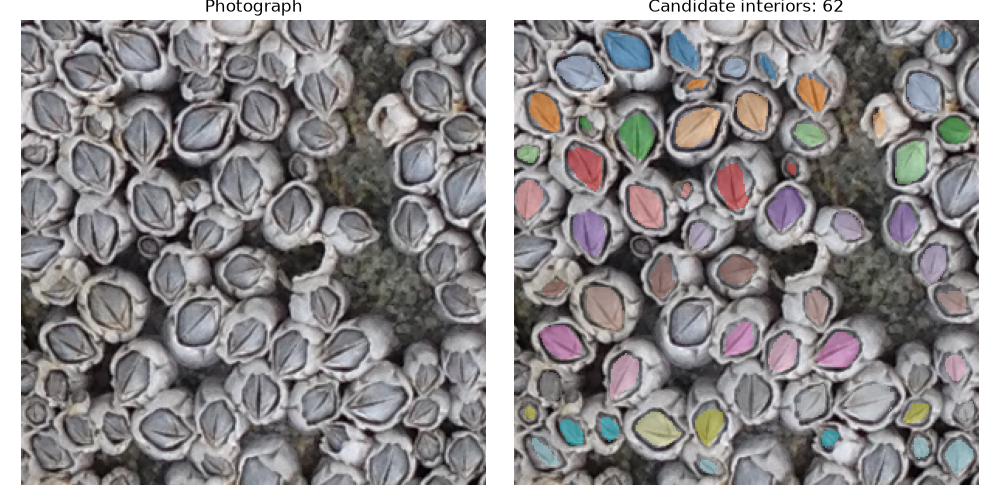

In [25]:
def show_instances(photo, instances, title):
    # Hide excluded pixels so the photograph remains visible underneath.
    # Only positive candidate IDs will receive an overlay color.
    # The underlying label map is unchanged.
    # example:
    # Instance IDs:    [0,    1,     1,     0,    2]
    # hidden positions: [True, False, False, True, False]
    visible_instances = np.ma.masked_where(
        instances == 0, # Pixels to hide.
        instances # Candidate IDs to display.
    )
    # Compare the photograph with the recovered candidates.
    fix, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    axes[0].imshow(photo)
    axes[0].set_title("Photograph")
    
    axes[1].imshow(photo)
    axes[1].imshow(
        visible_instances,
        cmap="tab20", # Use colors to distinguish neighboring candidates.
        alpha = 0.5, # Keep the photograph visible through the overlay.
        interpolation="nearest", # Keep the displayed label boundaries sharp.
    )
    
    axes[1].set_title(title)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_instances(
    photo = photo_crop,
    instances = candidate_instances,
    title = f"Candidate interiors: {instance_count}"
)

### Trying the same rule on the full annotation

The color bounds and region-labeling steps now need to work beyond the inspection crop. I apply them to the full annotation and inspect the resulting overlay.


In [26]:
# Apply the measured color rule to the full annotation.

full_outlines = extract_outlines(
    annotation,
    lower_blue,
    upper_blue
)
# Check that extraction preserves the image dimensions.
print("Full annotation shape:", annotation.shape)
print("Full outline mask shape:", full_outlines.shape)

Full annotation shape: (2448, 3264, 3)
Full outline mask shape: (2448, 3264)


The function below puts the outline inversion, connected-component labeling, border removal, and ID assignment together. It is the same recovery procedure used later for the second labeled photograph.


Full-image candidate interiors:: 2103


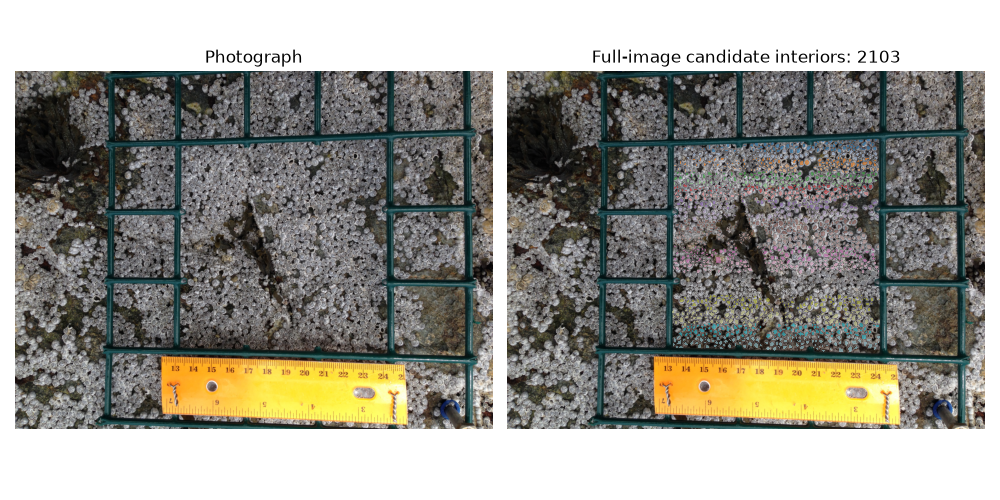

In [27]:
def recover_instances(outlines):
    # Turn the outlines into barriers between candidate regions.
    
    non_outline_pixels = cv2.bitwise_not(outlines)

    # Reuse the component-labeling, border-removal, and ID-assignment steps.
    number_of_labels, region_labels = label_regions(non_outline_pixels)

    keep = select_enclosed_regions(number_of_labels, region_labels)

    instances, instance_count = assign_instance_ids(region_labels, keep)

    return instances, instance_count

# Recover candidates from the complete annotation.

full_candidate_instances, full_instance_count = recover_instances(full_outlines)
print(f"Full-image candidate interiors:: {full_instance_count}")

# Inspect the recovered candidates over the full photograph.

show_instances(
    original_photo,
    full_candidate_instances,
    title=f"Full-image candidate interiors: {full_instance_count}"
)

## Choosing the counting regions

The scientists want the inside of the central sampling square, so I mark its four inner corners with sliders. The same polygon will be applied to the photograph and its reference labels.

The selector starts from the saved corners. Its preview is smaller for responsiveness, but the coordinates remain in original-image pixels.


In [28]:
# Use an interactive canvas to adjust the frame corners in place.



%matplotlib widget

from matplotlib.patches import Polygon

# Draw the photograph and selected counting boundary.
def preview_frame(photo, frame_corners):
    # frame_corners contains four (x,y) points, ordered around the boundary:
    # top-left, top-right, bottom-right, bottom-left
    # The preview keeps the original image's coordinate system.
    height, width = photo.shape[:2]

    # Make a smaller preview without altering the original image array.
    preview = Image.fromarray(photo)

    # Fit the preview inside 1000 × 1000 pixels while preserving proportions.
    
    preview.thumbnail((1000, 1000))

    # Create the figure without displaying an extra copy.
    # Its interactive canvas is placed beside the sliders below.
    with plt.ioff():
        fig, ax = plt.subplots(figsize=(9,7))

    # Map the smaller preview onto the original image dimensions.
    # left edge = x 0, right edge = x width
    # top edge = y 0, bottom edge = y height
    # slider values therefore remain in original-image coordinate units
    ax.imshow(
        preview,
        extent=(0, width, height, 0)
    )

    # Join the four corners with a yellow outline.
    # Close the polygon by joining the last corner to the first.
    # Leave the polygon unfilled so the photograph stays visible.
    ax.add_patch(Polygon(
        frame_corners,
        closed=True,
        fill=False,
        edgecolor="yellow",
        linewidth=2
    ))

    # Mark and label the four corners.

    corner_names = ["Top-left", "Top-right", "Bottom-right", "Bottom-left"]

    # Pair each corner name with its position.
    for name, (x,y) in zip(corner_names, frame_corners):
        ax.plot(x, y, "ro", markersize=5)
        # Offset the label slightly above and to the right of its marker.
        ax.annotate(
            name,
            (x,y),
            xytext=(5,5),
            textcoords="offset points",
            color="yellow"
        )

    ax.set_title("Selected sampling frame interior")
    ax.axis("off")
    fig.tight_layout()
    # Return the existing figure and axes for later updates.
    return fig, ax

# Update the same drawing whenever a slider changes.

def preview_frame_coordinates(photo, x0, y0, x1, y1, x2, y2, x3, y3, drawing):
    # Group the slider values in TL, TR, BR, BL order.
    corners = np.array([
        [x0, y0], # top left
        [x1, y1], # top right
        [x2, y2], # bottom right
        [x3, y3] # bottom left
    ])

    # Retrieve the figure and axes created by preview_frame().
    fig, ax = drawing

    # The first patch is the yellow polygon.
    # Replace its corners instead of adding another polygon.
    
    ax.patches[0].set_xy(corners)

    # Update the markers and labels in their original corner order.
    
    for marker, label, (x,y) in zip(ax.lines, ax.texts, corners):
        # Each marker contains a single point.
        marker.set_data([x], [y])
        
        # Move the label's anchor with the marker.
        label.xy = (x, y)

    # Request a redraw after the positions change.
    fig.canvas.draw_idle()

# Build the slider controls and their preview.
def create_frame_selector(photo, initial_corners=None):
    # Use this photograph's dimensions to set the slider limits.
    height, width = photo.shape[:2]

    # Reuse saved corners when supplied; otherwise start near the center.
    if initial_corners is None:
        initial_corners = [
            (width // 4, height // 4),
            (3 * width // 4, height // 4),
            (3 * width // 4, 3 * height // 4),
            (width // 4, 3 * height // 4),
        ]

    # Create the photograph, polygon, markers, and labels once.
    
    drawing = preview_frame(photo, initial_corners)

    corner_names = ["TL", "TR", "BR", "BL"]
    corner_sliders = {}

    # Each corner gets an x slider and a y slider.
    # Their names match the arguments of preview_frame_coordinates().
    # For example, x0 and y0 move the top-left corner.
    for index, (name, (x, y)) in enumerate(zip(corner_names, initial_corners)):
        corner_sliders[f"x{index}"] = widgets.IntSlider(
            value=x,
            min=0,
            max=width - 1,
            description = f"{name} x",
            continuous_update = True
        )

        corner_sliders[f"y{index}"] = widgets.IntSlider(
            value=y,
            min=0,
            max=height - 1,
            description = f"{name} y",
            continuous_update =True
        )
        
    # Connect slider changes to the drawing update.
    # ** passes the slider dictionary as named function arguments.
    frame_controls = widgets.interactive(
        preview_frame_coordinates,
        photo=widgets.fixed(photo),
        drawing=widgets.fixed(drawing),
        **corner_sliders
    )

    # Put the existing canvas beside the controls.
    display(widgets.HBox(
        [
            widgets.VBox(frame_controls.children[:-1]),
            drawing[0].canvas,
        ],
        layout=widgets.Layout(align_items="center")
    ))
    # Return the controls so their final coordinates can be saved.
    return frame_controls
    
    
# Start image 1's selector from its saved corners.
saved_labeled_regions = json.loads(Path("configs/regions.json").read_text())
frame_controls = create_frame_selector(
    original_photo, saved_labeled_regions["img1.png"]["frame_corners"]
)

Image 1's recovered masks are already available, so I keep those arrays and run the same recovery procedure only for image 2. I then select image 2's counting region with the same tool.


In [33]:
def get_frame_corners(controls):
    # Read the selected corners in TL, TR, BR, BL order.
    return np.array([
        [controls.kwargs[f"x{i}"], controls.kwargs[f"y{i}"]]
        for i in range(4)
    ], dtype = np.int32)

def prepare_samples(sample_id, data_dir, lower_blue, upper_blue):
    # Load a photograph and recover its candidate masks.
    with Image.open(data_dir / f"img{sample_id}.png") as image:
        photo = np.array(image.convert("RGB"))

    with Image.open(data_dir / f"mask{sample_id}.png") as image:
        annotation = np.array(image.convert("RGB"))

    assert photo.shape == annotation.shape, "Image dimensions must match"

    # Apply the same outline-recovery functions used for image 1.
    outlines = extract_outlines(annotation, lower_blue, upper_blue)
    instances, count = recover_instances(outlines)

    return {
        "photo": photo,
        "instances": instances,
        "instance_count": count
    }

# Reuse image 1's recovered masks and current frame selection.
samples = {
    1: {
        "photo": original_photo,
        "instances": full_candidate_instances,
        "instance_count":full_instance_count,
        "frame_corners":get_frame_corners(frame_controls)
    }
}

# Image 2 still needs its masks recovered.
samples[2] = prepare_samples(2, data_dir, lower_blue, upper_blue)
# Start image 2's selector from its saved corners.
sample2_controls = create_frame_selector(
    samples[2]["photo"], saved_labeled_regions["img2.png"]["frame_corners"]
)

### Keeping the selections and split

I use image 1 for training and image 2 for validation. Saving the split and selected corners means the model experiment can load these decisions after a kernel restart or on another machine.


In [41]:
import json

# Capture image 2's selection; image 1's is already in samples.
samples[2]["frame_corners"] = get_frame_corners(sample2_controls)

samples[1]["split"], samples[2]["split"] = "train", "val"

# Save the selections so they survive a kernel restart.
# The model section can then reuse them on another machine.
regions = {}

for sample_id, sample in samples.items():
    height, width = sample["photo"].shape[:2]
    filename = f"img{sample_id}.png"

    regions[filename] = {
        "width" : width,
        "height" : height,
        # Convert the coordinate array to a JSON-compatible list.
        "frame_corners": sample["frame_corners"].tolist(),
        "split":sample["split"]
    }
# Write the saved regions and split.
# Indent the JSON so the selections are easy to inspect.
regions_path = Path("configs/regions.json")
regions_path.write_text(
    json.dumps(regions, indent=2) + "\n",
)

# Show the split and corners that were written.
for filename, region in regions.items():
    print(f"{filename}: {region['split']}")
    print("Corners:", region["frame_corners"])
    
print(f"Saved to {regions_path}")

img1.png: train
Corners: [[1132, 513], [2527, 474], [2527, 1915], [1132, 1875]]
img2.png: val
Corners: [[948, 217], [2580, 218], [2553, 1875], [948, 1856]]
Saved to configs/regions.json


The recovered masks are already NumPy arrays inside `samples`. I save them together in a compressed NPZ file so the GPU experiment can load them without repeating the contour processing. The original photographs stay in `Barnacles/`, and the selected regions are saved separately in `configs/regions.json`.


In [42]:
instances_path = Path("data/processed/instances.npz")

np.savez_compressed(
    instances_path,
    img1=samples[1]["instances"],
    img2=samples[2]["instances"]
)
print(f"Saved existing instance label maps to {instances_path}")

Saved existing instance label maps to data/processed/instances.npz


### Selecting regions in the unseen photographs

I also record a counting region for each unseen photograph before running the model. The corners use the same order throughout: top-left, top-right, bottom-right, bottom-left.

The wider photograph has a sampling frame. The additional close-up has no frame, so I use its full extent as a separate qualitative test.


In [47]:
%matplotlib widget

from PIL import Image
with Image.open(data_dir / "unseen_img1.png") as image:
    unseen1_photo = np.array(image.convert("RGB"))

saved_unseen_regions = json.loads(Path("configs/test_regions.json").read_text())
unseen1_controls = create_frame_selector(
    unseen1_photo, saved_unseen_regions["unseen_img1.png"]
)

For the close-up, the saved selection covers the whole image. The selector uses this photograph's own dimensions for its slider limits.


In [48]:
with Image.open(data_dir / "unseen_img2.png") as image:
    unseen2_photo = np.array(image.convert("RGB"))

unseen2_controls = create_frame_selector(
    unseen2_photo, saved_unseen_regions["unseen_img2.png"]
)

Both selections go into `configs/test_regions.json`. This file tells the prediction code which area to count; it does not supply barnacle labels.


In [50]:
# Read the selected corners for both unseen photographs.
test_regions = {
    "unseen_img1.png": get_frame_corners(
        unseen1_controls
    ).tolist(),
    "unseen_img2.png":get_frame_corners(
        unseen2_controls
    ).tolist()
}

# Save the unseen regions alongside the labeled-image regions.
test_regions_path = Path("configs/test_regions.json")

test_regions_path.write_text(
    json.dumps(test_regions, indent=2) + "\n"
)

for filename, corners in test_regions.items():
    print(filename)
    print("Corners:", corners)

print(f"Saved to {test_regions_path}")

unseen_img1.png
Corners: [[1000, 217], [2553, 178], [2554, 1757], [1026, 1757]]
unseen_img2.png
Corners: [[0, 0], [499, 0], [499, 499], [0, 499]]
Saved to configs/test_regions.json


## Model experiment

I ran the model code in a Python terminal session on Dartmouth Discovery, then copied the figures and summaries back for this notebook. The cells below present that experiment in order and load the saved label maps and region files directly.

Run this section through **Predicting both unseen photographs** in the same CUDA-backed Python session. To inspect the completed run locally, skip to **Results** instead.


In [ ]:
from pathlib import Path
import csv
import json
import time

import cv2
import numpy as np
from PIL import Image
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

import torch
import torchvision
from torchvision.ops import masks_to_boxes
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights,
)
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

# Number of optimizer updates using the training photograph.
STEPS = 200
# Size of the optimizer adjustments during fine-tuning.
LEARNING_RATE = 1e-4
# Target length of the shorter image edge, in pixels.
SHORT_SIDE = 800
# Maximum longer-edge length; this limit takes priority while preserving proportions.
MAX_SIDE = 1024
# Maximum detections returned by the model for each image.
DETECTION_LIMIT = 2500
# Detection-confidence thresholds compared on the validation image.
CONFIDENCE_GRID = (0.3, 0.5, 0.7)
# Pixel-probability thresholds used to turn predicted masks into binary masks.
MASK_GRID = (0.4, 0.5, 0.6)
# Minimum mask intersection-over-union required for a validation match.
MATCH_IOU = 0.5

if not torch.cuda.is_available():
    raise RuntimeError("The model cells require CUDA-enabled PyTorch and an NVIDIA GPU.")

device = torch.device("cuda")
torch.manual_seed(42)
np.random.seed(42)
# Limit CPU computation to four threads.
torch.set_num_threads(4)

# Run from the project root so these paths locate the committed inputs.
root = Path.cwd()
data_dir = root / "Barnacles"
output_dir = root / "outputs"
# Create the results folder, reusing it when it already exists.
output_dir.mkdir(exist_ok=True)

regions = json.loads((root / "configs/regions.json").read_text())
test_regions = json.loads((root / "configs/test_regions.json").read_text())

for filename in test_regions:
    if not (data_dir / filename).exists():
        raise FileNotFoundError(f"Missing unseen photograph: {filename}")

def save_json(filename, data):
    (output_dir / filename).write_text(json.dumps(data, indent=2))

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0))

### Preparing the inputs

Each selected polygon is cropped to its bounding rectangle, with pixels outside the polygon set to black. I resize the region while keeping its proportions: the shorter edge targets 800 pixels, and the longer edge is limited to 1,024. Different photographs can therefore have different resized dimensions.

The reference labels receive the same crop and resize. Nearest-neighbor interpolation keeps the instance IDs intact. Single-pixel candidates are removed before resizing, and the counts are checked again afterward because some small regions can disappear.


In [ ]:
# Instance labels are supplied for training/validation and omitted for unseen images.
def prepare_region(photo, corners, instances=None):
    # Use integer coordinates for array indexing and OpenCV.
    corners = np.asarray(corners, dtype=np.int32)
    # Find the upper-left corner of the bounding rectangle.
    x0, y0 = corners.min(axis=0)
    # Include the final row and column: NumPy slices exclude their ending position.
    x1, y1 = corners.max(axis=0) + 1
    # Copy the crop so blacking out pixels does not alter the original photograph.
    crop = photo[y0:y1, x0:x1].copy()

    
    # Create a two-dimensional region mask matching the crop.
    frame = np.zeros(crop.shape[:2], dtype=np.uint8)
    # Move corners into crop coordinates and mark the polygon interior as 1.
    cv2.fillPoly(frame, [corners - [x0, y0]], 1)
    # Set pixels outside the selected polygon to black.
    crop[frame == 0] = 0

    # Read the crop dimensions for the resize calculation.
    height, width = frame.shape
    # Choose one resize factor that respects both size limits.
    scale = min(SHORT_SIDE / min(height, width), MAX_SIDE / max(height, width))
    # OpenCV expects dimensions in (width, height) order.
    size = (round(width * scale), round(height * scale))
    # Collect the photograph, frame mask, tensor, and optional reference labels.
    sample = {}

    if instances is not None:
        labels = instances[y0:y1, x0:x1].copy()
        # Background ID 0 excludes reference pixels outside the counting polygon.
        labels[frame == 0] = 0
        # Count the pixels assigned to each instance ID.
        areas = np.bincount(labels.ravel())
        # Discard single-pixel candidates before resizing.
        labels[areas[labels] == 1] = 0
        # Count remaining positive IDs; exclude background ID 0.
        sample["native_count"] = int(np.count_nonzero(np.bincount(labels.ravel())[1:]))
        # Nearest-neighbor interpolation preserves integer instance IDs.
        labels = cv2.resize(labels, size, interpolation=cv2.INTER_NEAREST)
        # Keep the resized reference labels for training or evaluation.
        sample["label_map"] = labels
        # Some small instances disappear during resizing; count only IDs still present.
        sample["count"] = int(np.count_nonzero(np.unique(labels)))

    # Resize the RGB photograph with area interpolation.
    sample["photo"] = cv2.resize(crop, size, interpolation=cv2.INTER_AREA)
    # Resize the polygon mask without blending values, then convert it to True/False.
    sample["frame"] = cv2.resize(frame, size, interpolation=cv2.INTER_NEAREST).astype(bool)
    # Convert RGB pixels to a channels-first PyTorch tensor with values between 0 and 1.
    sample["image"] = torch.from_numpy(sample["photo"]).permute(2, 0, 1).float() / 255
    return sample


# Store the prepared samples under their saved train/val split.
prepared = {}
# Reuse recovered instance maps without repeating contour extraction.
with np.load(root / "data/processed/instances.npz") as stored:
    for filename, region in regions.items():
        with Image.open(data_dir / filename) as image:
            photo = np.array(image.convert("RGB"))
        # Match the photograph to its saved region and NPZ key, such as img1.
        sample = prepare_region(photo, region["frame_corners"], stored[Path(filename).stem])
        # Keep training and validation samples separate.
        prepared[region["split"]] = sample
        print(f"{region['split']}: {sample['native_count']} candidates before resizing; "
              f"{sample['count']} after resizing")

### Fine-tuning the pretrained model

Mask R-CNN provides separate masks that can be displayed over the photograph and counted. I start from COCO-pretrained weights and replace the prediction heads for background and barnacle classes.

The experiment uses small-object anchors and 200 updates on image 1. Horizontal flips change the image, masks, and boxes together. Mixed precision reduces GPU memory use. Image 2 is kept out of the training gradients.


In [ ]:
anchors = AnchorGenerator(
    # Use small anchor boxes at the five feature-pyramid levels.
    sizes=((8,), (16,), (32,), (64,), (128,)),
    # Propose tall, square, and wide boxes at each level.
    aspect_ratios=((0.5, 1.0, 2.0),) * 5,
)
model = maskrcnn_resnet50_fpn(
    # Start from COCO-pretrained weights.
    weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT,
    # Keep the model resize limits consistent with preprocessing.
    min_size=SHORT_SIDE, max_size=MAX_SIDE,
    # Use the custom small-object anchors.
    rpn_anchor_generator=anchors,
    # Retain this many proposals before suppressing overlapping boxes.
    rpn_pre_nms_top_n_train=6000, rpn_pre_nms_top_n_test=6000,
    # Retain this many proposals after overlap suppression.
    rpn_post_nms_top_n_train=3000, rpn_post_nms_top_n_test=3000,
    box_detections_per_img=DETECTION_LIMIT,
)
# Replace the classification/box head for background and barnacle classes.
model.roi_heads.box_predictor = FastRCNNPredictor(
    model.roi_heads.box_predictor.cls_score.in_features, 2
)
# Replace the segmentation head for the same two classes.
model.roi_heads.mask_predictor = MaskRCNNPredictor(
    model.roi_heads.mask_predictor.conv5_mask.in_channels, 256, 2
)
# Move model parameters to the allocated GPU.
model.to(device)


def train_model(model, sample):
    # Move the input tensor to the GPU.
    image = sample["image"].to(device)
    # Move the reference instance IDs to the GPU.
    labels = torch.as_tensor(sample["label_map"], device=device)
    ids = np.unique(sample["label_map"])
    ids = torch.as_tensor(ids[ids > 0], device=device)
    # Create one binary reference mask for every positive instance ID.
    masks = (labels[None] == ids[:, None, None]).to(torch.uint8)
    # Derive bounding boxes from the reference masks.
    boxes = masks_to_boxes(masks)
    # Make maximum coordinates exclusive and retain valid boxes for thin masks.
    boxes[:, 2:] += 1
    target = {
        "boxes": boxes,
        # All foreground instances have barnacle class ID 1.
        "labels": torch.ones(len(ids), dtype=torch.int64, device=device),
        "masks": masks,
    }

    # Update the trainable parameters with AdamW and weight decay.
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    # Scale gradients to support mixed-precision training.
    scaler = torch.cuda.amp.GradScaler()
    history = []
    # Track elapsed training time.
    started = time.perf_counter()
    # Enable training behavior and loss computation.
    model.train()

    for step in range(1, STEPS + 1):
        current_image, current_target = image, target
        # Apply a horizontal flip with probability 0.5.
        if torch.rand(()).item() < 0.5:
            current_image = image.flip(-1)
            flipped_boxes = boxes.clone()
            # Mirror the left and right bounding-box coordinates along with the image.
            flipped_boxes[:, [0, 2]] = image.shape[-1] - boxes[:, [2, 0]]
            current_target = {
                **target, "boxes": flipped_boxes, "masks": masks.flip(-1)
            }

        # Clear gradients from the previous update.
        optimizer.zero_grad(set_to_none=True)
        # Use mixed precision to reduce GPU memory use.
        with torch.autocast(device_type="cuda"):
            loss = sum(model([current_image], [current_target]).values())
        # Read the loss for logging without retaining its computation graph.
        value = loss.detach().item()
        if not np.isfinite(value):
            raise RuntimeError(f"Non-finite loss at update {step}")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        # Limit the gradient norm to reduce unstable updates.
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        history.append(value)

        if step == 1 or step % 10 == 0:
            elapsed = time.perf_counter() - started
            print(f"Update {step}/{STEPS}: loss={value:.4f}, elapsed={elapsed:.0f}s",
                  flush=True)
    return history


history = train_model(model, prepared["train"])
# Release unused cached GPU memory after training.
torch.cuda.empty_cache()

### Comparing predictions with the recovered labels

The confidence threshold decides which detections to keep. The mask threshold decides which pixels belong to each detection. Reference masks are clipped to the counting region; a prediction is retained when its mask centroid lies inside that region, then its mask is clipped as well.

For validation, I work through predictions from highest to lowest confidence. A match needs mask intersection-over-union of at least 0.5, and a reference instance can be matched only once. Precision, recall, and F1 describe that matching; absolute count error compares the totals. All of these comparisons depend on the quality of the recovered reference masks.


In [ ]:
def collect_predictions(model, sample, confidence, mask_thresholds):
    model.eval()
    # Filter model detections by the requested confidence threshold.
    model.roi_heads.score_thresh = float(confidence)
    # Run prediction without building a gradient graph.
    with torch.inference_mode():
        prediction = model([sample["image"].to(device)])[0]

    # Read reference labels when evaluating the validation image.
    truth = sample.get("label_map")
    if truth is not None:
        ids = np.unique(truth)
        # Exclude background ID 0 from reference matching.
        ids = ids[ids > 0]
        # Precompute each reference instance area for IoU calculations.
        areas = np.bincount(truth.ravel())

    # Reuse one model forward pass across the requested mask thresholds.
    cache = {threshold: [] for threshold in mask_thresholds}
    if len(prediction["scores"]) == DETECTION_LIMIT:
        print("Detection limit reached; some predictions may be truncated.")

    for index, score in enumerate(prediction["scores"].cpu().tolist()):
        probability = prediction["masks"][index, 0].cpu().numpy()
        for threshold in mask_thresholds:
            # Convert pixel probabilities into a binary predicted mask.
            mask = probability >= np.float32(threshold)
            # Find the mask pixels and use their mean position as its centroid.
            ys, xs = np.nonzero(mask)
            # Exclude empty masks and predictions whose centroid is outside the polygon.
            if len(xs) == 0 or not sample["frame"][int(ys.mean()), int(xs.mean())]:
                continue

            x0, x1 = int(xs.min()), int(xs.max()) + 1
            y0, y1 = int(ys.min()), int(ys.max()) + 1
            # Store only the bounding crop, clipped to the counting region.
            cropped = mask[y0:y1, x0:x1] & sample["frame"][y0:y1, x0:x1]
            area = int(cropped.sum())
            if area == 0:
                continue

            # Keep the score, bounding coordinates, and exact binary mask together.
            candidate = {"score": score, "box": (x0, y0, x1, y1), "mask": cropped.copy()}
            if truth is not None:
                intersection = np.bincount(
                    truth[y0:y1, x0:x1][cropped], minlength=len(areas)
                )[ids]
                # IoU is intersection area divided by union area.
                union = area + areas[ids] - intersection
                candidate["iou"] = (intersection / np.maximum(union, 1)).astype(np.float32)
            cache[threshold].append(candidate)
    return cache


def keep_predictions(candidates, confidence):
    return [p for p in candidates if np.float32(p["score"]) > np.float32(confidence)]


def evaluate(candidates, reference_count, confidence, mask_threshold):
    kept = keep_predictions(candidates, confidence)
    # Track which reference instances have already been matched.
    matched = np.zeros(reference_count, dtype=bool)
    true_positive = 0

    for candidate in sorted(kept, key=lambda p: p["score"], reverse=True):
        if reference_count == 0:
            break
        overlaps = candidate["iou"].copy()
        # Prevent several predictions from matching the same reference.
        overlaps[matched] = -1
        # Choose the remaining reference with the greatest overlap.
        best = int(overlaps.argmax())
        # Accept only matches reaching the required mask IoU.
        if overlaps[best] >= MATCH_IOU:
            matched[best] = True
            true_positive += 1

    count = len(kept)
    return {
        "confidence_threshold": float(confidence),
        "mask_threshold": float(mask_threshold),
        # Fraction of retained predictions that match a reference.
        "precision": true_positive / max(count, 1),
        # Fraction of reference instances matched by a prediction.
        "recall": true_positive / max(reference_count, 1),
        # Balance precision and recall using their harmonic mean.
        "f1": 2 * true_positive / max(count + reference_count, 1),
        "predicted_count": count,
        "absolute_count_error": abs(count - reference_count),
    }

### Choosing the inference thresholds

I compare the confidence and mask thresholds in the grids above, giving nine combinations. One model prediction supplies the masks for all of them, so this search does not require retraining.

I choose the highest instance F1, breaking ties by lower count error and then closeness to the baseline pair of 0.5 and 0.5. The learning rate and training duration stay fixed. The selected inference thresholds are used unchanged on both unseen photographs.


In [ ]:
# Use the held-out photograph without updating model weights.
validation = prepared["val"]
# Collect predictions once at the lowest candidate confidence.
cache = collect_predictions(model, validation, min(CONFIDENCE_GRID), MASK_GRID)

# Evaluate all confidence/mask-threshold combinations.
rows = [
    evaluate(cache[mask], validation["count"], confidence, mask)
    for mask in MASK_GRID
    for confidence in CONFIDENCE_GRID
]
# Maximize F1, then prefer lower count error and thresholds closer to 0.5.
best = max(rows, key=lambda row: (
    row["f1"], -row["absolute_count_error"],
    -abs(row["confidence_threshold"] - 0.5) - abs(row["mask_threshold"] - 0.5),
))
baseline = next(row for row in rows
                if row["confidence_threshold"] == 0.5 and row["mask_threshold"] == 0.5)

settings = {
    "confidence_threshold": best["confidence_threshold"],
    "mask_threshold": best["mask_threshold"],
    "short_side": SHORT_SIDE,
    "max_side": MAX_SIDE,
    "selection_metric": "instance F1 at mask IoU 0.5",
}
with (output_dir / "validation_tuning.csv").open("w", newline="") as file:
    # Save every evaluated combination as a CSV row.
    writer = csv.DictWriter(file, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

# Save the selected settings for interpreting the unseen predictions.
save_json("inference_settings.json", settings)
save_json("validation_summary.json", {
    "reference_status": "provisional recovered annotations",
    "native_resolution_candidate_count": validation["native_count"],
    "working_resolution_candidate_count": validation["count"],
    "baseline": baseline,
    "selected": best,
})
print("Baseline:", baseline)
print("Selected:", best)

I save the training loss curve and a three-panel validation figure before moving to the unseen images. In the mask panel, colors distinguish individual predictions; they are all the same barnacle class.


In [ ]:
def save_figure(fig, filename):
    fig.tight_layout()
    # Save a figure that can be viewed outside the GPU session.
    fig.savefig(output_dir / filename, dpi=160, bbox_inches="tight")
    # Close the figure to avoid accumulating plots in memory.
    plt.close(fig)


def show_prediction(sample, candidates, confidence, title, filename):
    kept = sorted(keep_predictions(candidates, confidence),
                  key=lambda p: p["score"], reverse=True)
    # Start the overlay from the photograph.
    overlay = sample["photo"].copy()
    # Use a black background for the instance-mask panel.
    colored = np.zeros_like(overlay)
    # Assign repeatable display colors to the individual instances.
    colors = np.random.default_rng(42).integers(
        40, 256, size=(len(kept), 3), dtype=np.uint8
    )

    # Draw higher-confidence predictions last where masks overlap.
    for index in range(len(kept) - 1, -1, -1):
        candidate = kept[index]
        x0, y0, x1, y1 = candidate["box"]
        mask, color = candidate["mask"], colors[index]
        color_patch = colored[y0:y1, x0:x1]
        overlay_patch = overlay[y0:y1, x0:x1]
        photo_patch = sample["photo"][y0:y1, x0:x1]
        # Color only pixels belonging to this predicted mask.
        color_patch[mask] = color
        # Blend the mask color with the original photograph.
        overlay_patch[mask] = (0.55 * photo_patch[mask] + 0.45 * color).astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(17, 6))
    for ax, pixels, label in zip(
        axes,
        [sample["photo"], colored, overlay],
        ["Photograph", "Predicted instance masks", f"Overlay: {len(kept)} instances"],
    ):
        ax.imshow(pixels)
        ax.set_title(label)
        ax.axis("off")
    # Label the entire three-panel figure.
    fig.suptitle(title)
    save_figure(fig, filename)
    return len(kept)


fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(history) + 1), history)
ax.set(xlabel="Training update", ylabel="Total loss", title="Mask R-CNN training")
save_figure(fig, "loss_curve.png")

show_prediction(
    validation, cache[settings["mask_threshold"]], settings["confidence_threshold"],
    "Validation image 2", "validation_prediction.png",
)
del cache

### Predicting both unseen photographs

The loop below loads each saved region, applies the trained model with the selected thresholds, and saves its overlay and count summary. There are no reference masks for these photographs, so this step produces predictions rather than a measured test score.


In [ ]:
for filename, corners in test_regions.items():
    with Image.open(data_dir / filename) as image:
        photo = np.array(image.convert("RGB"))
    sample = prepare_region(photo, corners)
    threshold = settings["mask_threshold"]
    predictions = collect_predictions(
        model, sample, settings["confidence_threshold"], [threshold]
    )[threshold]

    # Remove the extension to name the summary and figure for this image.
    stem = Path(filename).stem
    # Save the prediction figure and retrieve the retained instance count.
    count = show_prediction(
        sample, predictions, settings["confidence_threshold"],
        filename, f"{stem}_prediction.png",
    )
    # Record the prediction count, selected region, and inference settings.
    save_json(f"{stem}_summary.json", {
        "image": filename,
        "predicted_count": count,
        "frame_corners": corners,
        **settings,
    })
    print(f"{filename}: {count:,} predicted instances", flush=True)

print(f"Finished. Results saved in {output_dir}")

## Results

These figures and summaries came from the completed Discovery run. This cell only reads the saved files, so it can be run locally without executing the GPU section. The table compares the baseline and F1-selected settings; `validation_tuning.csv` contains the full threshold search.


| Setting | Confidence | Mask | Precision | Recall | F1 | Count | Count error|
|---|---:|---:|---:|---:|---:|---:|---:|
| Baseline | 0.5 |0.5 | 0.091 | 0.137 | 0.109 | 614 | 204 |
| Selected | 0.3 |0.5 | 0.094 | 0.232 | 0.134 | 1013 | 603 |

Validation reference instances after resizing: 410


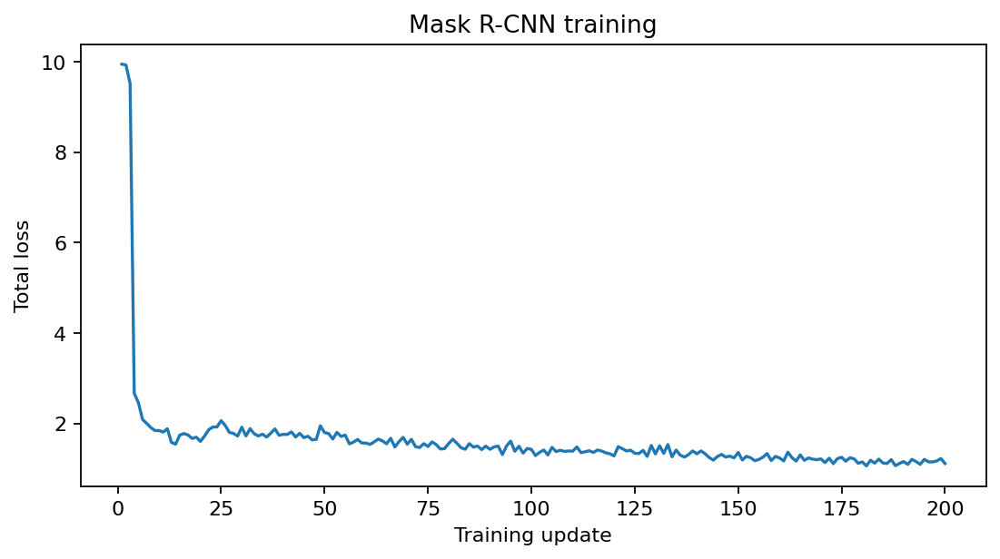

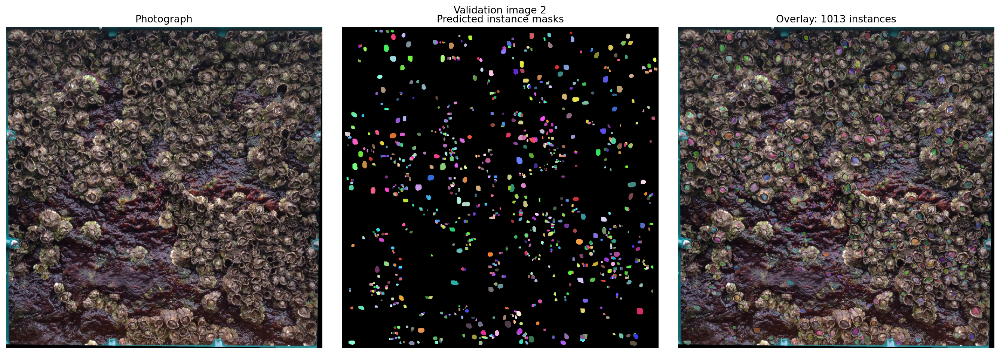

**unseen_img1.png: 1,039 predicted instances**

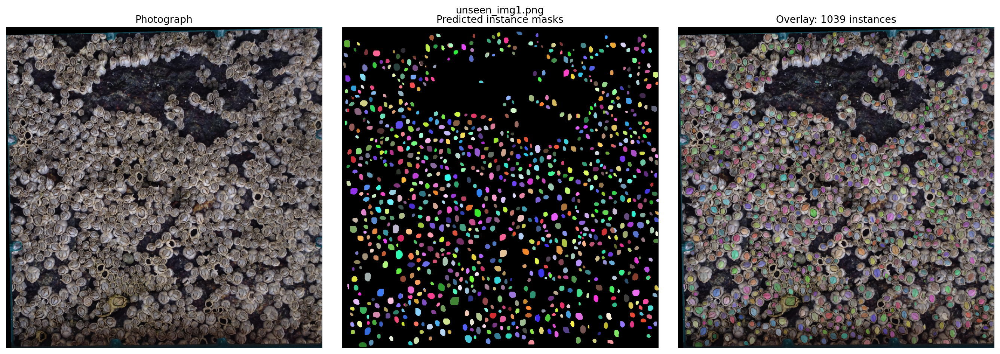

**unseen_img2.png: 864 predicted instances**

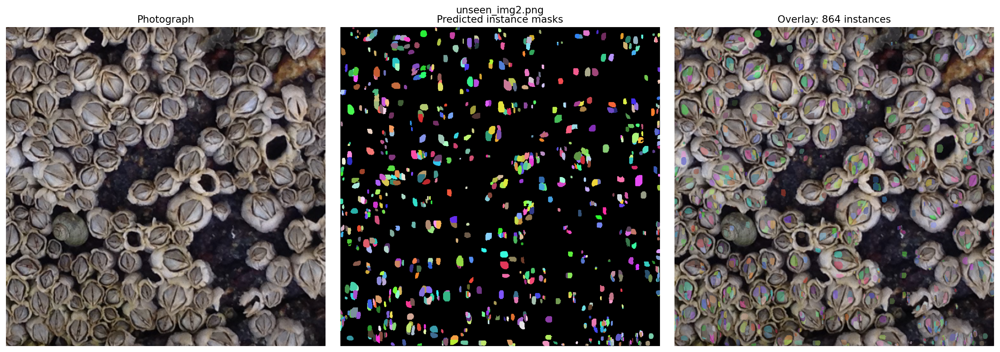

In [69]:
from pathlib import Path
import json
from IPython.display import display, Markdown, Image as DisplayImage

results = Path("outputs")
summary = json.loads((results / "validation_summary.json").read_text())
table = [
    "| Setting | Confidence | Mask | Precision | Recall | F1 | Count | Count error|",
    "|---|---:|---:|---:|---:|---:|---:|---:|"
]

for name in ("baseline", "selected"):
    m = summary[name]
    table.append(
        f"| {name.title()} | {m['confidence_threshold']:.1f} |"
        f"{m['mask_threshold']:.1f} | {m['precision']:.3f} | "
        f"{m['recall']:.3f} | {m['f1']:.3f} | "
        f"{m['predicted_count']} | {m['absolute_count_error']} |"
    )

display(Markdown("\n".join(table)))

print("Validation reference instances after resizing:", summary["working_resolution_candidate_count"])

for filename in ("loss_curve.png", "validation_prediction.png"):
    display(DisplayImage(filename=str(results/filename)))

saved_regions = json.loads(Path("configs/test_regions.json").read_text())

for filename in saved_regions:
    # Match the saved result names by removing the image extension.
    # For example, unseen_img1.png becomes unseen_img1.
    stem = Path(filename).stem

    # Load the saved summary for this image.
    # Its predicted count is displayed above the segmentation figure.
    record = json.loads((results / f"{stem}_summary.json").read_text())
    display(Markdown(
        f"**{filename}: {record['predicted_count']:,} predicted instances**"
    ))
    display(DisplayImage(filename=str(results / f"{stem}_prediction.png")))

## Interpretation and limitations

Unseen image 1 is the most encouraging visual result. Many predicted masks follow individual barnacle interiors across the dense clusters, while the large exposed-rock area receives few predictions. This suggests that the model learned useful visual cues that carry over to this photograph, although its count is still unverified.

The falling training loss shows adaptation to the training example, but validation agreement remains weak. On unseen image 2, some barnacles receive several small, partial predictions, suggesting sensitivity to scale and appearance. The experiment does not isolate perspective as the cause.

The small dataset and automatically recovered labels limit the conclusions. I would audit those masks and test more varied scales with additional labeled photographs. The current overlays offer a promising starting point for human review; their counts still need checking.
